In [1]:
import pandas as pd

In [2]:
a = pd.read_csv("../data/curated/data_lin_reg_before_onehotencode.csv")

a.head()

,property type,beds,baths,parking,weekly rent amount,postcode,distance primary school,distance secondary school,is closest school good,distance university campus,...,city_centre,closest_city_centre,coastal,closest_cc_dist,dist_to_melb,predicted median equivalised total household income (weekly) ($) 2023,predicted median weekly household rental payment ($) 2023,predicted average family size (no. of persons) 2023,predicted employment ratio 2023,predicted total dwellings (no.) 2023
0,House,1,2,6,120,3127,0.586504,2.491226,True,7.430317,...,False,Melbourne,False,11.566742,12.618789,1567.422222,487.077778,3.030000,0.952619,18091.000000
1,House,9,2,2,130,3216,1.372612,2.438191,False,0.675843,...,False,Geelong,False,7.459818,71.172437,1172.308333,403.983333,3.019167,0.956643,31411.666667
2,House,1,1,0,140,3936,4.858273,3.301447,True,47.278807,...,False,Cranbourne,False,37.174742,58.248165,985.433333,429.133333,2.700000,0.967222,9143.000000
3,House,1,2,6,140,3216,1.114181,1.998214,False,1.502495,...,False,Geelong,False,7.459818,71.172437,1172.308333,403.983333,3.019167,0.956643,31411.666667
4,House,1,4,3,150,3216,0.215009,1.989564,False,1.862509,...,False,Geelong,False,7.459818,71.172437,1172.308333,403.983333,3.019167,0.956643,31411.666667


In [3]:
melbourne_df = a[a["closest_city_centre"] == "Melbourne"]

In [5]:
melbourne_post = melbourne_df["postcode"].unique()

In [3]:
a.columns

Index(['property type', 'beds', 'baths', 'parking', 'weekly rent amount',
       'postcode', 'distance primary school', 'distance secondary school',
       'is closest school good', 'distance university campus',
       'distance to closest hospital', 'offence count 2023',
       'estimated resident population (no.) 2011',
       'estimated resident population (no.) 2016',
       'estimated resident population (no.) 2021', 'city_centre',
       'closest_city_centre', 'coastal', 'closest_cc_dist', 'dist_to_melb',
       'predicted median equivalised total household income (weekly) ($) 2023',
       'predicted median weekly household rental payment ($) 2023',
       'predicted average family size (no. of persons) 2023',
       'predicted employment ratio 2023',
       'predicted total dwellings (no.) 2023'],
      dtype='object')

In [7]:
df_2011 = pd.read_csv("../data/curated/postcode_info_2011.csv")
df_2016 = pd.read_csv("../data/curated/postcode_info_2016.csv")
df_2021 = pd.read_csv("../data/curated/postcode_info_2021.csv")


In [10]:
df_2011.shape

(427, 12)

In [9]:
df_2011[df_2011["Postcode"].isin(melbourne_post)]

,Postcode,Estimated resident population (no.),Employed (no.),Unemployed (no.),In the Labour force (no.),Total persons aged 15 years and over (no.),Land area (ha),Total families (no.),Total dwellings (no.),Median equivalised total household income (weekly) ($),Median weekly household rental payment ($),Average family size (no. of persons)
0,3000,163110.0,55833.0,4270.0,60108.0,97390.0,0.0,23110.0,84200.0,1017.090909,402.090909,2.481818
1,3002,5495.0,3122.0,109.0,3234.0,4630.0,0.0,1087.0,3057.0,1504.000000,420.000000,2.300000
2,3003,23087.0,7840.0,706.0,8558.0,13921.0,0.0,3015.0,11018.0,1014.000000,395.000000,2.500000
3,3004,109938.0,38469.0,2536.0,41011.0,63808.0,0.0,15049.0,60992.0,1120.000000,417.625000,2.387500
4,3006,34462.0,12197.0,696.0,12899.0,19496.0,0.0,4936.0,19536.0,1257.000000,483.500000,2.350000
...,...,...,...,...,...,...,...,...,...,...,...,...
326,3764,14385.0,5379.0,287.0,5663.0,9401.0,0.0,3204.0,5768.0,700.000000,240.000000,3.100000
327,3765,7123.0,3426.0,129.0,3556.0,5438.0,0.0,1808.0,2488.0,794.000000,251.000000,3.200000
328,3775,14226.0,6061.0,256.0,6311.0,10301.0,0.0,3523.0,5791.0,674.000000,250.000000,3.000000
329,3777,14226.0,6061.0,256.0,6311.0,10301.0,0.0,3523.0,5791.0,674.000000,250.000000,3.000000


In [24]:
df_2011['Year'] = 2011
df_2016['Year'] = 2016
df_2021['Year'] = 2021

combined_df = pd.concat([df_2011[df_2011["Postcode"].isin(melbourne_post)], 
                         df_2016[df_2016["Postcode"].isin(melbourne_post)], 
                         df_2021[df_2021["Postcode"].isin(melbourne_post)]])

In [9]:
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from matplotlib import pyplot as plt

# Assuming combined_df has been created as described previously

# Check for stationarity using Dickey-Fuller test
def test_stationarity(timeseries):
    result = adfuller(timeseries)
    print('ADF Statistic: %f' % result[0])
    print('p-value: %f' % result[1])
    if result[1] <= 0.05:
        print("Data is stationary")
    else:
        print("Data is non-stationary")

# Iterate over each unique postcode
postcodes = combined_df['Postcode'].unique()

predicted_rental_2024 = {}

for postcode in postcodes:
    print(f"Processing for postcode: {postcode}")
    df_postcode = combined_df[combined_df['Postcode'] == postcode].sort_values(by="Year")
    
    test_stationarity(df_postcode['Median weekly household rental payment ($)'])
    
    # If data is non-stationary, you might need to difference the series or transform it 
    # For simplicity, let's assume it's stationary. You can adjust based on the results.
    
    model = ARIMA(df_postcode['Median weekly household rental payment ($)'], order=(0, 1, 0))

    model_fit = model.fit(disp=0)
    
    # Forecasting for 2024
    forecast = model_fit.forecast(steps=1)  # steps=1 since we're predicting just one year ahead
    predicted_rental_2024[postcode] = forecast[0]

print(predicted_rental_2024)


Processing for postcode: 3000


ValueError: sample size is too short to use selected regression component

In [25]:
combined_df

,Postcode,Estimated resident population (no.),Employed (no.),Unemployed (no.),In the Labour force (no.),Total persons aged 15 years and over (no.),Land area (ha),Total families (no.),Total dwellings (no.),Median equivalised total household income (weekly) ($),Median weekly household rental payment ($),Average family size (no. of persons),Year
0,3000,163110.0,55833.0,4270.0,60108.0,97390.0,0.0,23110.0,84200.0,1017.090909,402.090909,2.481818,2011
1,3002,5495.0,3122.0,109.0,3234.0,4630.0,0.0,1087.0,3057.0,1504.000000,420.000000,2.300000,2011
2,3003,23087.0,7840.0,706.0,8558.0,13921.0,0.0,3015.0,11018.0,1014.000000,395.000000,2.500000,2011
3,3004,109938.0,38469.0,2536.0,41011.0,63808.0,0.0,15049.0,60992.0,1120.000000,417.625000,2.387500,2011
4,3006,34462.0,12197.0,696.0,12899.0,19496.0,0.0,4936.0,19536.0,1257.000000,483.500000,2.350000,2011
...,...,...,...,...,...,...,...,...,...,...,...,...,...
326,3764,15517.0,7214.0,336.0,7557.0,12650.0,46152.3,4243.0,6420.0,965.000000,330.000000,3.000000,2021
327,3765,6995.0,3494.0,114.0,3607.0,5582.0,1054.3,1920.0,2513.0,1141.000000,365.000000,3.100000,2021
328,3775,14181.0,6719.0,220.0,6933.0,11666.0,36952.4,3931.0,5945.0,980.000000,350.000000,2.900000,2021
329,3777,14181.0,6719.0,220.0,6933.0,11666.0,36952.4,3931.0,5945.0,980.000000,350.000000,2.900000,2021


In [26]:
def compute_growth_rate(df):
    # Calculate growth rate between 2016 and 2021
    int_col = 'Median weekly household rental payment ($)'
    growth_rate_1 = (df.iloc[2][int_col] - df.iloc[1][int_col]) / df.iloc[1][int_col]
    growth_rate_2 = (df.iloc[1][int_col] - df.iloc[0][int_col]) / df.iloc[0][int_col]
    return (growth_rate_1 + growth_rate_2)/2

growth_rates = {}
postcodes = combined_df['Postcode'].unique()

for postcode in postcodes:
    df_postcode = combined_df[combined_df['Postcode'] == postcode].sort_values(by="Year")
    growth_rates[postcode] = compute_growth_rate(df_postcode)
    

sorted_growth_rates = {k: v for k, v in sorted(growth_rates.items(), key=lambda item: item[1], reverse=True)}
top_10_postcodes = list(sorted_growth_rates.keys())[:10]
bottom_10_postcodes = list(sorted_growth_rates.keys())[:-10]


In [43]:
top_10_postcodes = list(sorted_growth_rates.keys())[:10]
bottom_10_postcodes = list(sorted_growth_rates.keys())[-10:]

In [44]:
bottom_10_postcodes

[3181, 3754, 3206, 3067, 3000, 3205, 3004, 3003, 3006, 3008]

In [46]:
top_bottom_10_postcodes = top_10_postcodes + bottom_10_postcodes

In [42]:
sorted_growth_rates

{3335: 0.4206377299839693,
 3340: 0.25284933645589386,
 3431: 0.2445054945054945,
 3066: 0.2379637809187279,
 3434: 0.23333333333333334,
 3435: 0.23333333333333334,
 3717: 0.225,
 3437: 0.21791187739463602,
 3438: 0.21791187739463602,
 3765: 0.2140555425357394,
 3714: 0.2137482900136799,
 3022: 0.20716278306531016,
 3016: 0.20485586822237473,
 3025: 0.20245382723800553,
 3751: 0.19971264367816094,
 3757: 0.19971264367816094,
 3015: 0.19419504643962848,
 3012: 0.1912680412966073,
 3081: 0.18837873754152823,
 3029: 0.18807324684673082,
 3775: 0.1837704918032787,
 3777: 0.1837704918032787,
 3013: 0.18356060606060606,
 3019: 0.18339534883720932,
 3024: 0.18200575953306863,
 3011: 0.1771190397714788,
 3658: 0.17261904761904762,
 3764: 0.17261904761904762,
 3115: 0.17260776629853936,
 3091: 0.17142857142857143,
 3171: 0.17051282051282052,
 3070: 0.16774899167039492,
 3113: 0.16656321619556913,
 3071: 0.1665558142112848,
 3190: 0.16392458595945542,
 3018: 0.16380718954248366,
 3194: 0.1635769

In [27]:
print(top_10_postcodes)

[3335, 3340, 3431, 3066, 3434, 3435, 3717, 3437, 3438, 3765]


In [28]:
sorted_growth_rates

{3335: 0.4206377299839693,
 3340: 0.25284933645589386,
 3431: 0.2445054945054945,
 3066: 0.2379637809187279,
 3434: 0.23333333333333334,
 3435: 0.23333333333333334,
 3717: 0.225,
 3437: 0.21791187739463602,
 3438: 0.21791187739463602,
 3765: 0.2140555425357394,
 3714: 0.2137482900136799,
 3022: 0.20716278306531016,
 3016: 0.20485586822237473,
 3025: 0.20245382723800553,
 3751: 0.19971264367816094,
 3757: 0.19971264367816094,
 3015: 0.19419504643962848,
 3012: 0.1912680412966073,
 3081: 0.18837873754152823,
 3029: 0.18807324684673082,
 3775: 0.1837704918032787,
 3777: 0.1837704918032787,
 3013: 0.18356060606060606,
 3019: 0.18339534883720932,
 3024: 0.18200575953306863,
 3011: 0.1771190397714788,
 3658: 0.17261904761904762,
 3764: 0.17261904761904762,
 3115: 0.17260776629853936,
 3091: 0.17142857142857143,
 3171: 0.17051282051282052,
 3070: 0.16774899167039492,
 3113: 0.16656321619556913,
 3071: 0.1665558142112848,
 3190: 0.16392458595945542,
 3018: 0.16380718954248366,
 3194: 0.1635769

In [47]:
top_bottom_df = combined_df[combined_df["Postcode"].isin(top_bottom_10_postcodes)][["Postcode", "Median weekly household rental payment ($)", "Year"]]

In [32]:
import seaborn as sns
import matplotlib.pyplot as plt

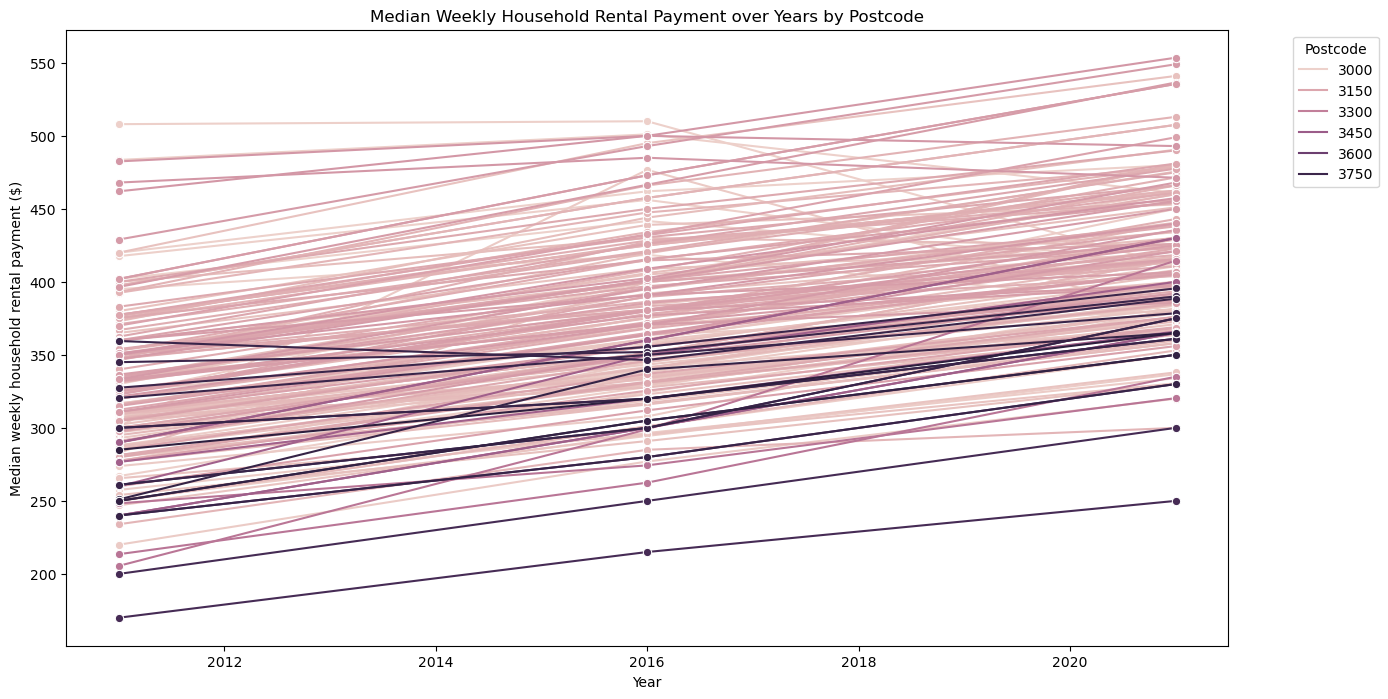

In [33]:
plt.figure(figsize=(15, 8))  # Set the figure size
sns.lineplot(data=combined_df, x='Year', y='Median weekly household rental payment ($)', hue='Postcode', marker='o')
plt.title('Median Weekly Household Rental Payment over Years by Postcode')
plt.legend(title='Postcode', bbox_to_anchor=(1.05, 1), loc='upper left')  # Place legend outside the plot
plt.show()

In [49]:
top_bottom_df["Postcode"] = top_bottom_df["Postcode"].astype(str)

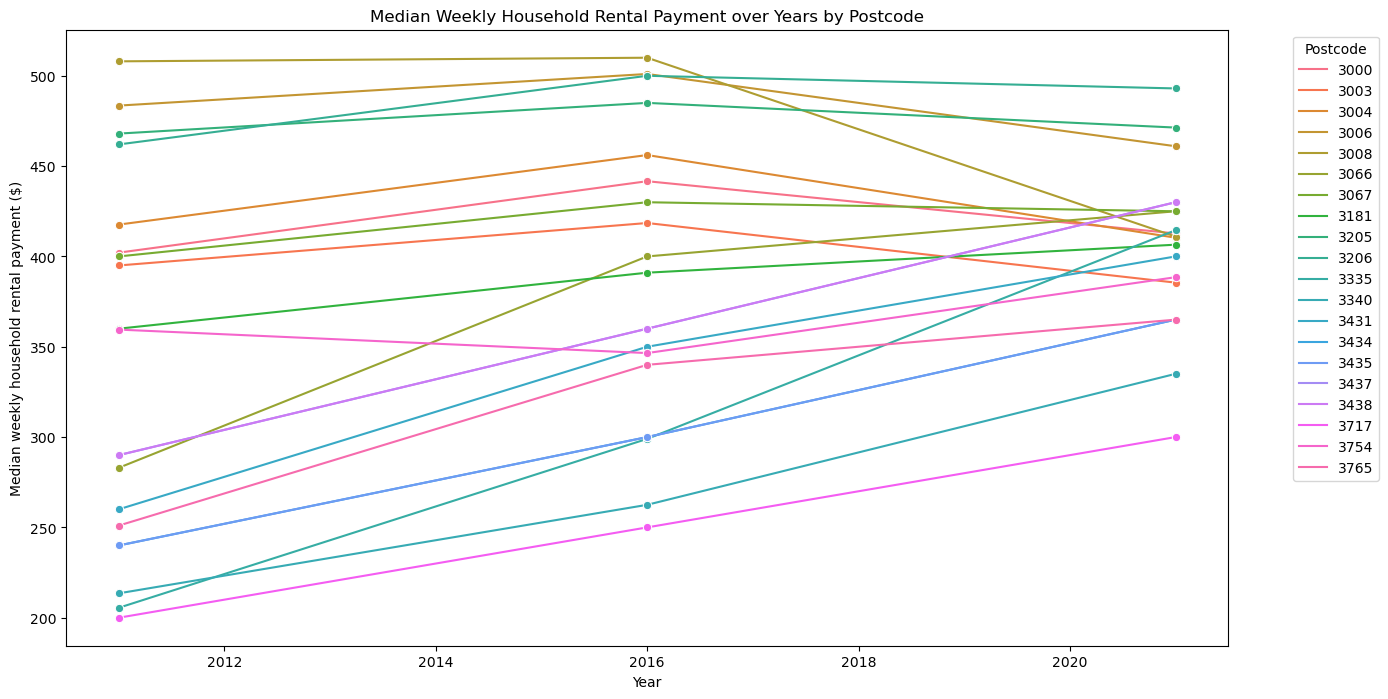

In [50]:
plt.figure(figsize=(15, 8))  # Set the figure size
sns.lineplot(data=top_bottom_df, x='Year', y='Median weekly household rental payment ($)', hue='Postcode', marker='o')
plt.title('Median Weekly Household Rental Payment over Years by Postcode')
plt.legend(title='Postcode', bbox_to_anchor=(1.05, 1), loc='upper left')  # Place legend outside the plot
plt.show()

In [15]:
sorted_growth_rates = {k: v for k, v in sorted(predicted_rental_2024.items(), key=lambda item: item[1], reverse=True)}


NameError: name 'predicted_rental_2024' is not defined